In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from hidro_tools import funcion_objetivo
from hidro_tools import funciones_hidrologicas
from pysheds.grid import Grid
from pysheds.view import Raster, ViewFinder
import funciones_chirps as fc
import delimitacion_cuenca as dc
from pathlib import Path
import xarray as xr
import rioxarray 
import glob
import re
import random
import os
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Delimitacion cuencas zona

In [97]:
crs = 9377
gdf = gpd.read_file('CNE_actualizado')
gdf = gdf.to_crs(crs)
mask = gdf['Codigo'] == '22057010'
est_piedra_cobre = gdf[mask].copy()
lon = est_piedra_cobre.get_coordinates().iloc[0,0]
lat = est_piedra_cobre.get_coordinates().iloc[0,1]

In [98]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)

dem_9377 = dem.rio.reproject(
    'EPSG:9377',
    resolution=30,   # ajusta a tu resolución original (m); evita celdas no cuadradas o remuestreo no deseado
)

In [99]:
# Delimitacion cuencas
path_guardado = 'cuencas_estaciones'
estaciones = ['22057070','22057060']
path_estaciones = 'q_data'
files = os.listdir(path_estaciones)
for file in files:
    cod = file.split('-')[0][2:]
    if cod in estaciones:
        mask = gdf['Codigo'] == cod
        df_estacion = gdf[mask].copy()
        nombre = df_estacion['Nombre'].iloc[0] + '.tif'
        name_path = os.path.join(path_guardado,nombre)
        # Extraccion georreferenciacion
        lon = df_estacion.get_coordinates().iloc[0,0]
        lat = df_estacion.get_coordinates().iloc[0,1]
        # Punto de desfogue
        outlet_estacion = (float(lon), float(lat))
        # Delimitacion
        cuenca = dc.delimitacion_cuenca(
            dem_9377,
            outlet_estacion,
            name_path,
            True
        )

KeyboardInterrupt: 

In [ ]:
outlet_estacion = (float(lon), float(lat))
cuenca = dc.delimitacion_cuenca(dem_9377,outlet_estacion,'cuenca_saldana.tif')

## Modelo Hidrológico 
Se ajustan modelos de lluvia escorrentía Velez et al (2000) y GR4J.
Insumos:
- Precipitación CHIRPS 1981 - 2026 promediada zonalmente a nivel de cuenca
- ETP: Inicialmente Cenicafé, para ajuste inicial, luego se pueden utilizar otras entradas como Turc, Hargreaves o Thornwaite

### Precipitación IDEAM

In [94]:
# Se recortan los datos del CNE con la cuenca de Saldaña
cuenca_saldana = gpd.read_file('cuenca_saldana')
cne = gpd.read_file('CNE_actualizado')
cne = cne.to_crs(cuenca_saldana.crs)
# Clipeo de los datos
cne_clipped = cne.clip(cuenca_saldana)
cne_clipped.loc[:,'Fecha_inst'] = pd.to_datetime(cne_clipped['Fecha_inst']) 

/tmp/ipykernel_5202/1005381965.py:7: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cne_clipped.loc[:,'Fecha_inst'] = pd.to_datetime(cne_clipped['Fecha_inst'])


In [95]:
categorias = ['Pluviométrica','Pluviográfica']
mask = (cne_clipped['Categoria'].isin(categorias)) & \
    (cne_clipped['Estado'] == 'Activa') & \
    (cne_clipped['Fecha_inst'] <= pd.to_datetime('2000-01-01'))
    
estaciones_pptn = cne_clipped[mask] 
estaciones_pptn.set_index('Codigo',drop=True,inplace=True)

In [96]:
# Estacion IDEAM
path = 'pptn_colombia'
files = os.listdir(path)

dict_files = {
    'files_path' : [os.path.join(path,file) for file in files],
    'cods' : [file.split('@')[1].split('.')[0] for file in files]
}
df_files = pd.DataFrame.from_dict(dict_files)
# Actualizacion
df_files.set_index('cods',drop=True,inplace=True)
# join de los dataframes
estaciones_pptn['files_path'] = df_files['files_path'].copy()

FileNotFoundError: [Errno 2] No such file or directory: 'pptn_colombia'

In [5]:
# Retener estaciones
columnas = ['Nombre','Fecha_inst','X','Y','files_path','geometry']
estaciones_pptn = estaciones_pptn[columnas]

In [6]:
# Fechas de las estaciones
fecha_minima = estaciones_pptn['Fecha_inst'].min()
fecha_superior = '2025-12-31'
date_range = pd.date_range(
    fecha_minima,
    fecha_superior,
    freq='D'
)

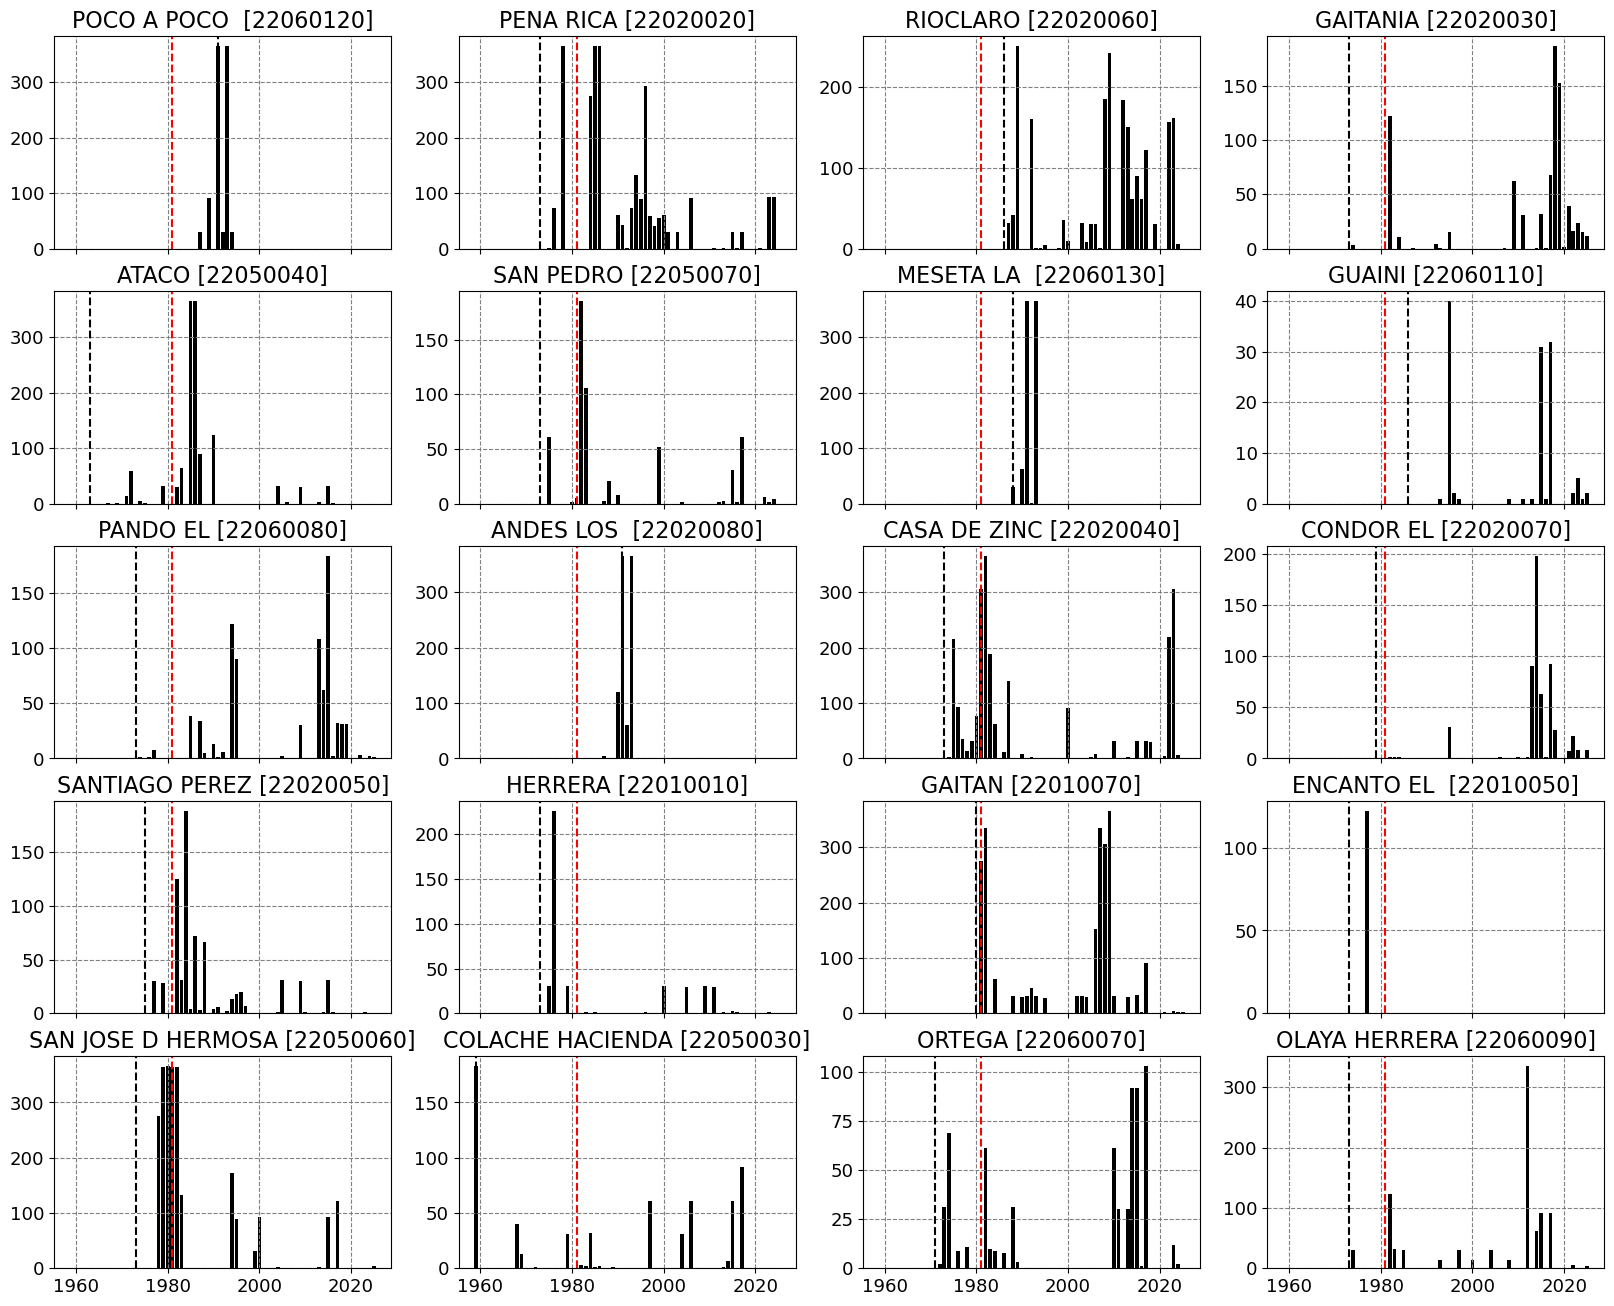

In [7]:
from hidro_tools import funciones_hidrologicas
# Chequeo de la consistencia de la informacion
figs, axes = plt.subplots(5,4,figsize=(20,16),sharex=True)
axis = axes.flatten()
fecha_chirps = 1981
for idx,cod in enumerate(estaciones_pptn.index):

    path_file = estaciones_pptn.at[cod,'files_path']
    fecha_estacion = estaciones_pptn.at[cod,'Fecha_inst'].year
    nombre = estaciones_pptn.at[cod,'Nombre']

    # Lectura de datos
    df = funciones_hidrologicas.read_data(path_file)
    # faltantes
    df_faltantes = df.isna().groupby(df.index.year).sum()
    # ploteo
    x = df_faltantes.index
    y = df_faltantes.iloc[:,0]
    axis[idx].bar(x=x,height=y,color='black')
    axis[idx].set_title(nombre,fontsize=16)
    # axis[idx].ylabel('Faltantes',fontsize=16)
    axis[idx].tick_params(axis='both', labelsize=13)
    axis[idx].grid(linestyle='--',color='grey')
    # Lineas chirps
    axis[idx].axvline(
        x=fecha_chirps,
        color='r',
        linestyle="--",
        linewidth=1.5, 
        label="CHIRPS"
    )
    # Linea estacion
    axis[idx].axvline(
        x=fecha_estacion,
        color='black',
        linestyle="--",
        linewidth=1.5, 
        label="estacion"
    )

### Precipitación Chirps

In [100]:
das = []
for f in sorted(glob.glob('chirps_tifs/chirps_*.tif')):
    da = rioxarray.open_rasterio(f)
    year = int(re.search(r'chirps_(\d{4})\.tif', f).group(1))
    fechas = pd.date_range(f'{year}-01-01', periods=da.sizes['band'], freq='D')
    das.append(da.assign_coords(band=fechas).rename(band='time'))

pptn = xr.concat(das, dim='time')

/home/jta/miniconda3/envs/cds/lib/python3.14/site-packages/rioxarray/_io.py:1146: RuntimeWarning: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
  if riods.subdatasets:
/home/jta/miniconda3/envs/cds/lib/python3.14/site-packages/rioxarray/_io.py:1146: RuntimeWarning: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
  if riods.subdatasets:
/home/jta/miniconda3/envs/cds/lib/python3.14/site-packages/rioxarray/_io.py:1146: RuntimeWarning: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
  if riods.subdatasets:
/home/jta/miniconda3/envs/cds/lib/python3.14/site-packages/rioxarray/_io.py:1146: RuntimeWarning: TIFFReadDirectory:Sum of Photometric type-related color channe

In [101]:
# Cargar cuenca
path = 'cuenca_saldana'
cuenca_saldana = gpd.read_file(path)
# Cambiar crs
crs = pptn.rio.crs
cuenca_saldana = cuenca_saldana.to_crs(crs)

In [102]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)
dem = dem.rio.reproject('EPSG:9377', resolution=30)

In [103]:
def clip_a_cuenca(da, gdf):
    g = gdf.to_crs(da.rio.crs)
    return da.rio.clip(g.geometry.values, crs=da.rio.crs, drop=True)

In [104]:
clip_pptn = clip_a_cuenca(pptn, cuenca_saldana)
clip_dem  = clip_a_cuenca(dem, cuenca_saldana)

### Ajuste de sesgo

Chequear el numero de faltantes de cada estacion, se retienen aquellas con menos del 35% de faltantes.

In [105]:
estaciones_pptn = pd.read_csv('estaciones_pptn_saldana.csv',index_col=0)

In [106]:
# Extraccion de faltantes
def faltantes(cod):
    path = estaciones_pptn.at[cod,'files_path']
    df = pd.read_csv(
        path,
        index_col=0,
        parse_dates=True
    )
    # ajuste a la resolucion de chirps
    df =  df.resample('D').mean()
    fecha = '1981-01-01'
    mask = df.index > fecha
    df_slice = df[mask]
    # faltantes
    faltantes = 100*(df_slice.isna().sum().iloc[0]/len(df_slice))
    faltantes = np.round(faltantes,2)
    return faltantes

estaciones_pptn['faltantes'] = estaciones_pptn.index.map(faltantes)

/tmp/ipykernel_5202/281108309.py:15: RuntimeWarning: invalid value encountered in scalar divide
  faltantes = 100*(df_slice.isna().sum().iloc[0]/len(df_slice))


In [107]:
# dropeo estaciones con muchos faltantes
umbral = 30
mask = estaciones_pptn['faltantes'] < umbral
estaciones_pptn_slice = estaciones_pptn[mask]

In [108]:
estaciones_pptn # Crear un dataset vacio

# Array vacio para luego interpolar
array = pptn[0,:,:] * 0 + np.nan

for idx,cod in enumerate(estaciones_pptn_slice.index):
    
    # Lectura de los datos
    path = estaciones_pptn_slice.at[cod,'files_path']

    df = pd.read_csv(
        path,
        index_col=0,
        parse_dates=True
    )
    # ajuste a la resolucion de chirps
    df =  df.resample('D').mean()
    
    # codigo = re.findall(re_pattern, prueba)[0]
    pptn_anual_ideam = funciones_hidrologicas.pptn_media_anual(df)
    # extraccion de los datos
    coord_x = estaciones_pptn_slice.loc[cod,'X']
    coord_y = estaciones_pptn_slice.loc[cod,'Y']
    # Extraccion de datos chirps
    pptn_chirps = pptn.sel(
        x=coord_x,
        y=coord_y,
        method='nearest'
    )
    df_pptn_chirps = pptn_chirps.to_dataframe('pptn')
    df_pptn_chirps = df_pptn_chirps[['pptn']]
    # Estimacion media 
    media_chirps = funciones_hidrologicas.pptn_media_anual(df_pptn_chirps)
    # estimacion correccion
    correccion = pptn_anual_ideam/media_chirps
    # seleccion puntos array
    x_array = array.x.sel(
        x=coord_x,
        method='nearest'
    )
    y_array = array.y.sel(
        y=coord_y,
        method='nearest'
    )
    #diccionario asignacio datos
    dict_arreglo = dict(
        x=x_array,
        y=y_array
    )
    # asignacion
    array.loc[dict_arreglo] = correccion

In [109]:
arreglo_sesgo = fc.idw_interpolate_dataarray(array)

In [110]:
# correccion precipitacion
pptn_corregida = pptn * arreglo_sesgo

### Modelo de Tanques

#### Calibracion

Se aplica una calibracion - validacion 70 - 30.

In [113]:
fechas = pd.date_range('2005','2020',freq='D')
nro_dias = len(fechas)
fecha_cal = int(nro_dias*0.7)
fecha_f = fechas[fecha_cal]

In [139]:
dict_fechas = {
    '22057070':('2005',fecha_f),
    '22057010':('2005',fecha_f)
}
dict_area = {
    '22057070':6422.64,
    '22057010':7742.234,
}
path_cuencas = {
    '22057070':'cuencas_estaciones/pte_colache.shp',
    '22057010':'cuenca_saldana/cuenca_saldana.shp',
}
path_data = {
    '22057070':'q_data/0022057070-Q_MEDIA_D.csv',
    '22057010':'q_data/0022057010-Q_MEDIA_D.csv',
}

In [116]:
def clip_a_cuenca(da, gdf):
    g = gdf.to_crs(da.rio.crs)
    return da.rio.clip(g.geometry.values, crs=da.rio.crs, drop=True)

def read_q_data(cod):
        # Lectura de datos
    df_q = pd.read_csv(
        path_data[cod],
        index_col=0,
        parse_dates=True,
        usecols=[0,1]
    )
    df_q = df_q.resample('D').mean()

    return df_q

In [117]:
from hidro_tools import funcion_objetivo   # ajusta a tu estructura
from hidro_tools import modelo_tanques
MT = modelo_tanques.modelo_tanques

resultados, dict_simulaciones = {}, {}
cods = ['22057070','22057010']
pesos = {'Nash': 0.0, 'Nash_mod': 1.0, 'Balance': 0.}
dict_q_obs = dict()
dict_pptn = dict()
dict_sim = dict()
dict_puntaje = dict()
dict_mejores = dict()
for cod in cods:

    # Lectura de datos
    df_q = read_q_data(cod)
    # Preparacion de la informacion
    fecha_i,fecha_f = dict_fechas[cod]
    mask = (df_q.index >= fecha_i) & (df_q.index < fecha_f)
    q_obs = np.asarray(df_q[mask].iloc[:,0])
    dict_q_obs[cod] = q_obs
    # Delimitacion de la cuenca 
    gdf = gpd.read_file(path_cuencas[cod])
    # arreglo precipitacion
    da_pptn = clip_a_cuenca(pptn_corregida,gdf)
    da_pptn_cuenca = da_pptn.mean(axis=1).mean(axis=1)
    df_pptn = da_pptn_cuenca.to_dataframe('pptn')
    mask = (df_pptn.index >= fecha_i) & (df_pptn.index < fecha_f)
    pptn_cuenca = (df_pptn[mask].iloc[:,1])
    dict_pptn[cod] = pptn_cuenca
    # Cota 
    clip_dem = clip_a_cuenca(clip_dem,gdf)
    cota = clip_dem.mean(axis=0).mean(axis=0).values

    dict_mejores[cod], dict_sim[cod], dict_puntaje[cod] = MT.calibrar(
    pptn_cuenca, q_obs, cota, dict_area[cod],
    fobj=funcion_objetivo,
    fijos={'perdidas_subt': 0},
    calentamiento=180,
    maxiter=10000,
    seed=42,
    pesos = pesos,
    )

    # resultados[cod], dict_simulaciones[cod] = MT.montecarlo(
    #     pptn_cuenca, 
    #     q_obs,
    #     cota,            # en vez del 2134.65 fijo
    #     area=dict_area[cod],
    #     fobj=funcion_objetivo,
    #     n_iter=5000,
    #     fijos={'perdidas_subt': 0},     # opcional
    #     calentamiento=180,              # opcional, días excluidos de las métricas
    #     seed=42,                        # opcional, para repetir la corrida
    # )

In [118]:
dict_puntaje

{'22057070': np.float64(0.29883), '22057010': np.float64(0.39798)}

In [119]:
# Chequeo resultados'
cod = '22057010'
# df = resultados[cod]
q_obs_ = dict_q_obs[cod]
q_sim = dict_sim[cod]
pptn_cuenca_ = dict_pptn[cod]
mejor_params = dict_mejores[cod]
  # mismo índice que el DataFrame

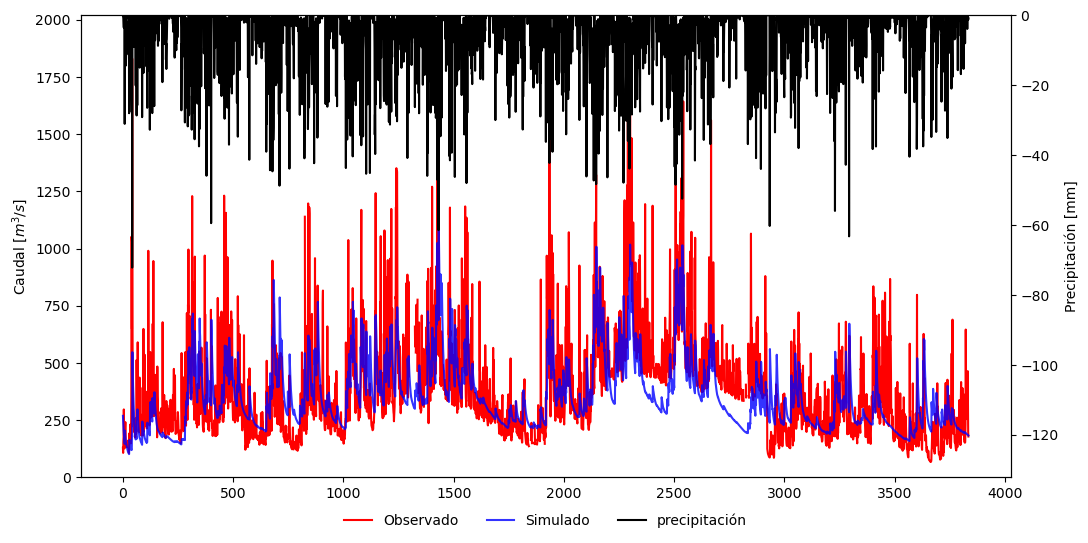

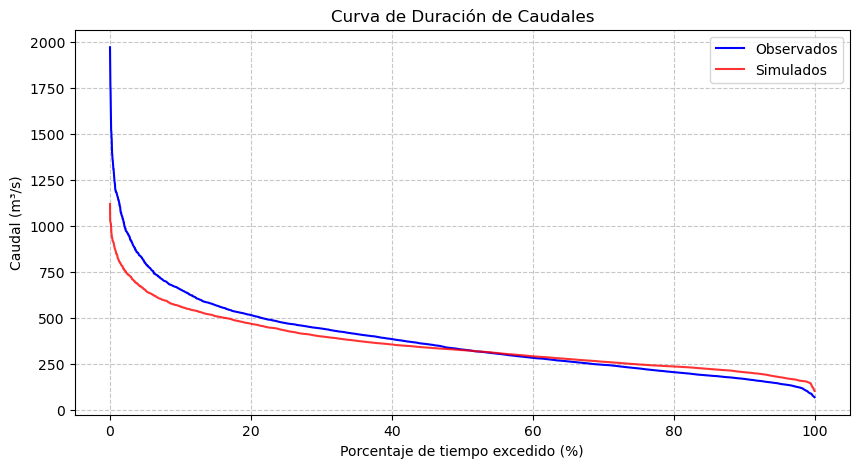

In [120]:
MT.plot_resultados(None,q_obs_, q_sim, pptn_cuenca_)
MT.curva_duracion(None,q_obs_, q_sim)

#### Validacion

In [121]:
cod = '22057010'
fecha_i,fecha_f_val = fecha_f,'2020'
df = read_q_data(cod)
mask = (df_q.index >= fecha_i) & (df_q.index <= fecha_f_val)
q_obs = np.asarray(df_q[mask].iloc[:,0])
gdf = gpd.read_file(path_cuencas[cod])
    # arreglo precipitacion
da_pptn = clip_a_cuenca(pptn_corregida,gdf)
da_pptn_cuenca = da_pptn.mean(axis=1).mean(axis=1)
df_pptn = da_pptn_cuenca.to_dataframe('pptn')
mask = (df_pptn.index >= fecha_i) & (df_pptn.index <= fecha_f_val)
pptn_cuenca = (df_pptn[mask].iloc[:,1])
params = dict_mejores[cod]
clip_dem = clip_a_cuenca(clip_dem,gdf)
cota = clip_dem.mean(axis=0).mean(axis=0).values

params = [params[k] for k in MT.NOMBRES_PARAMS]
modelo = MT(pptn_cuenca, *params, cota, dict_area[cod])
q_sim, q_base = modelo.correr()

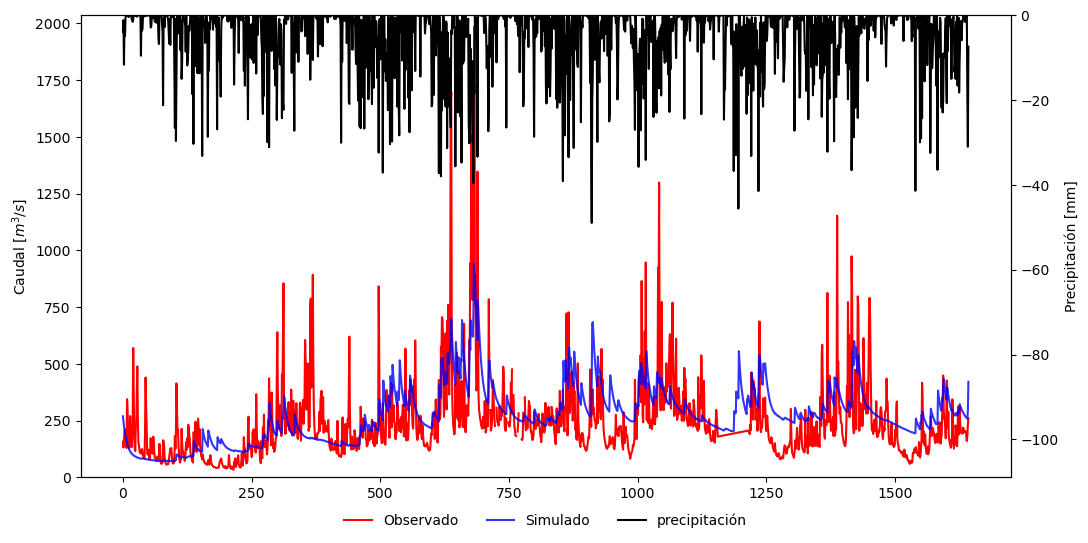

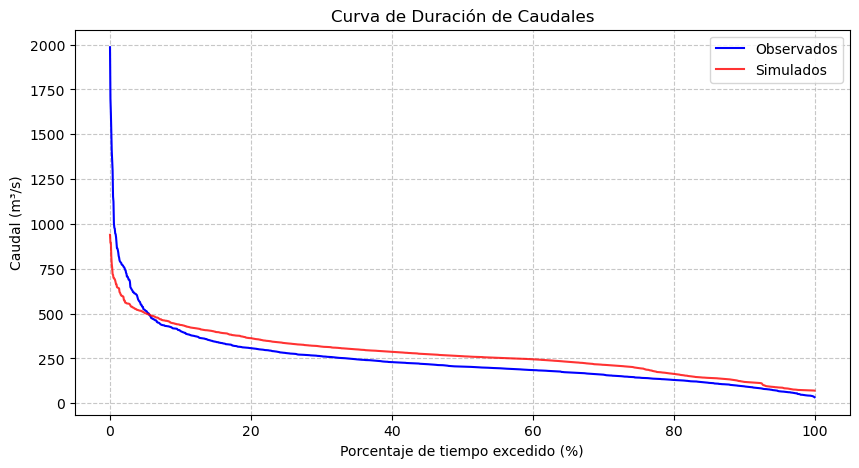

In [122]:
MT.plot_resultados(None,q_obs, q_sim, pptn_cuenca)
MT.curva_duracion(None,q_obs, q_sim)

## Estimacion maximos, minimos y medios


#### Rellenar estacion

In [169]:
cod = '22057010'
gdf = gpd.read_file(path_cuencas[cod])
da_pptn = clip_a_cuenca(pptn_corregida,gdf)
da_pptn_cuenca = da_pptn.mean(axis=1).mean(axis=1)
df_pptn = da_pptn_cuenca.to_dataframe('pptn')
df_pptn = df_pptn[['pptn']]
# lectura de datos
q_piedras_cobre = read_q_data(cod)

In [170]:
fecha_i_relleno, fecha_f_relleno = '2000','2026'
dates = pd.date_range(fecha_i_relleno,fecha_f_relleno,freq='D')
params = dict_mejores[cod]
mask = (q_piedras_cobre.index >= fecha_i_relleno) & (q_piedras_cobre.index < fecha_f_relleno)
q_piedras_cobre = np.asarray(q_piedras_cobre[mask].iloc[:,0])
mask = (df_pptn.index >= fecha_i_relleno) & (df_pptn.index < fecha_f_relleno)
df_pptn = np.asarray(df_pptn[mask].iloc[:,0])
params = [params[k] for k in MT.NOMBRES_PARAMS]
clip_dem = clip_a_cuenca(dem,gdf)
cota = clip_dem.mean(axis=0).mean(axis=0).values
modelo = MT(df_pptn, *params, cota, dict_area[cod])
q_sim, q_base = modelo.correr()
df_simulado = pd.DataFrame(
    np.asarray(q_sim),
    index=dates[:-1],
    columns=['valorObservado']
)

In [ ]:
# datos rellenados
q_piedras_cobre = read_q_data(cod)
df_rellenado = q_piedras_cobre.fillna(df_simulado)